<a href="https://colab.research.google.com/github/baroonda/Actividad_6_DEAG/blob/main/Actividad_6_DEAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


ROC AUC Promedio en CV (Random Forest): 0.9452 (+/- 0.0202)

--- Resultados Modelo A (Tráfico Baseline) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42647
           1       0.78      0.64      0.70        74

    accuracy                           1.00     42721
   macro avg       0.89      0.82      0.85     42721
weighted avg       1.00      1.00      1.00     42721


--- Resultados Modelo B (Tráfico Random Forest) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42648
           1       0.97      0.76      0.85        74

    accuracy                           1.00     42722
   macro avg       0.98      0.88      0.92     42722
weighted avg       1.00      1.00      1.00     42722


Umbral sugerido para priorizar Recall >= 85%: 0.1000


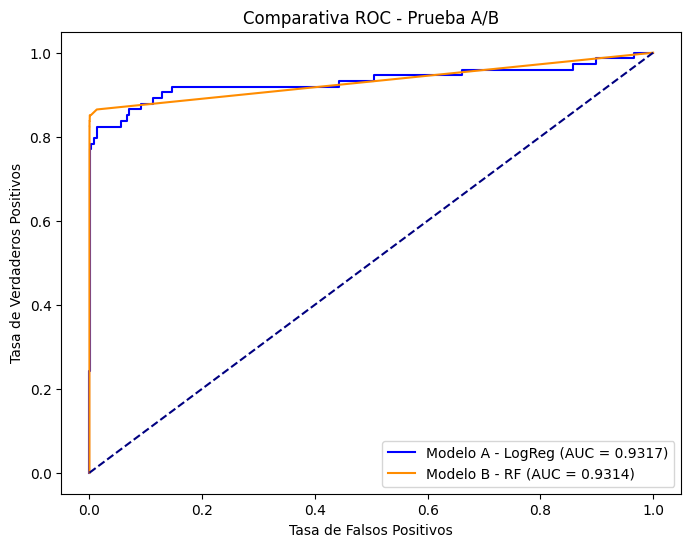

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve

# 1. Carga de Datos (Sube creditcard.csv a Colab previamente)
df = pd.read_csv('/content/creditcard.csv')

# Separar características y variable objetivo (Class: 1 Fraude, 0 Genuina)
X = df.drop('Class', axis=1)
y = df['Class']

# Simulación de división temporal para Prueba A/B offline y validación
# Usaremos el 70% para entrenar, 30% para simular el entorno de producción (Prueba A/B)
X_train, X_prod, y_train, y_prod = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Dividir el entorno de producción en dos flujos para la Prueba A/B (50% de tráfico a cada modelo)
X_test_A, X_test_B, y_test_A, y_test_B = train_test_split(X_prod, y_prod, test_size=0.5, random_state=42, stratify=y_prod)

# 2. Entrenamiento de Modelos
# Modelo A (Baseline): Regresión Logística
modelo_a = LogisticRegression(max_iter=1000)
modelo_a.fit(X_train, y_train)

# Modelo B (Principal): Random Forest (n_estimators reducido por rendimiento en Colab)
modelo_b = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
modelo_b.fit(X_train, y_train)

# 3. Validación Cruzada en Random Forest
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_cv = cross_val_score(modelo_b, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"ROC AUC Promedio en CV (Random Forest): {scores_cv.mean():.4f} (+/- {scores_cv.std() * 2:.4f})")

# 4. Simulación de Prueba A/B
y_pred_A = modelo_a.predict(X_test_A)
y_pred_prob_A = modelo_a.predict_proba(X_test_A)[:, 1]

y_pred_B = modelo_b.predict(X_test_B)
y_pred_prob_B = modelo_b.predict_proba(X_test_B)[:, 1]

print("\n--- Resultados Modelo A (Tráfico Baseline) ---")
print(classification_report(y_test_A, y_pred_A))

print("\n--- Resultados Modelo B (Tráfico Random Forest) ---")
print(classification_report(y_test_B, y_pred_B))

# 5. Ajuste de Umbral (Threshold Tuning) para Modelo B
# En fraude, preferimos aumentar el Recall (detectar más fraudes) aunque caiga la Precisión
#precisions, recalls, thresholds = precision_recall_curve(y_test_B, y_pred_prob_B)
# Buscar umbral donde el recall sea al menos 85%
#umbral_optimo = thresholds[np.argmax(recalls >= 0.85)]
#print(f"\nUmbral sugerido para priorizar Recall >= 85%: {umbral_optimo:.4f}")

# 5. Ajuste de Umbral (Threshold Tuning) CORREGIDO
precisions, recalls, thresholds = precision_recall_curve(y_test_B, y_pred_prob_B)

# Buscar el índice del umbral más alto que aún mantenga un recall >= 0.85
# (La lista de recalls tiene un elemento extra, por eso filtramos con [:-1])
indices_validos = np.where(recalls[:-1] >= 0.85)[0]
indice_optimo = indices_validos[-1]
umbral_optimo = thresholds[indice_optimo]

print(f"\nUmbral sugerido para priorizar Recall >= 85%: {umbral_optimo:.4f}")

# 6. Gráficas ROC AUC Comparativas
fpr_A, tpr_A, _ = roc_curve(y_test_A, y_pred_prob_A)
roc_auc_A = auc(fpr_A, tpr_A)

fpr_B, tpr_B, _ = roc_curve(y_test_B, y_pred_prob_B)
roc_auc_B = auc(fpr_B, tpr_B)

plt.figure(figsize=(8, 6))
plt.plot(fpr_A, tpr_A, color='blue', label=f'Modelo A - LogReg (AUC = {roc_auc_A:.4f})')
plt.plot(fpr_B, tpr_B, color='darkorange', label=f'Modelo B - RF (AUC = {roc_auc_B:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Comparativa ROC - Prueba A/B')
plt.legend(loc="lower right")
plt.show()

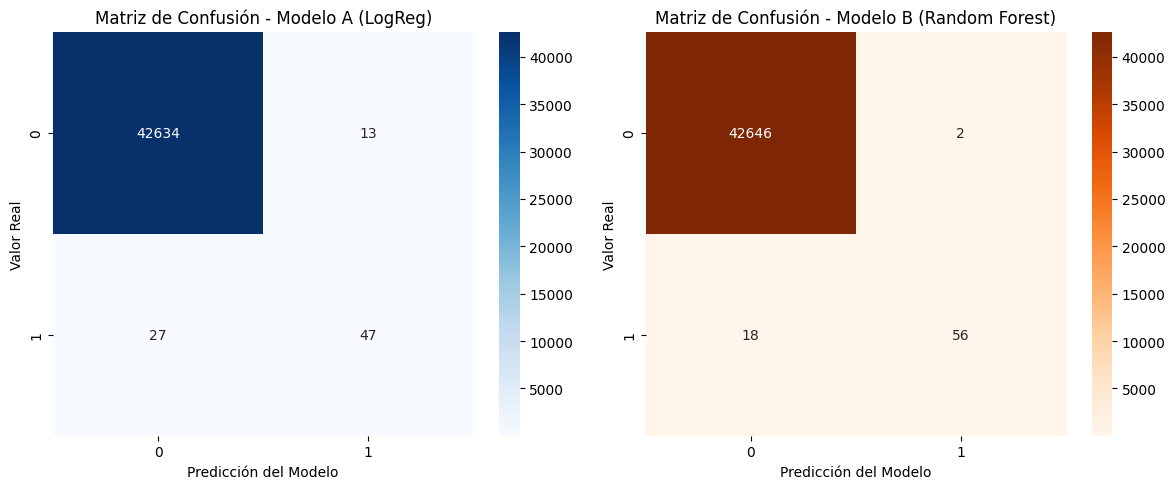

In [ ]:
# 7. Generación de Matrices de Confusión
cm_A = confusion_matrix(y_test_A, y_pred_A)
cm_B = confusion_matrix(y_test_B, y_pred_B)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfica para Regresión Logística
sns.heatmap(cm_A, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - Modelo A (LogReg)')
axes[0].set_xlabel('Predicción del Modelo')
axes[0].set_ylabel('Valor Real')

# Gráfica para Random Forest
sns.heatmap(cm_B, annot=True, fmt='d', cmap='Oranges', ax=axes[1])
axes[1].set_title('Matriz de Confusión - Modelo B (Random Forest)')
axes[1].set_xlabel('Predicción del Modelo')
axes[1].set_ylabel('Valor Real')

plt.tight_layout()
plt.show()